# Introducción a la visualización de datos con Python

## Objetivos

Al terminar este cuaderno podrás:

- Explicar para qué sirve la visualización de datos.
- Elegir un gráfico adecuado según la pregunta que quieras responder.
- Crear gráficos con `matplotlib`.
- Crear gráficos directamente a partir de un `DataFrame` de `pandas`.
- Personalizar títulos, ejes, leyendas y colores.
- Interpretar la información que muestra un gráfico.

## Bibliotecas que utilizaremos

- **Pandas**: para organizar y manipular los datos en tablas.
- **Matplotlib**: para construir y personalizar gráficos.

Estas bibliotecas se deben importar con `import`. 

```python
import pandas as pd
import matplotlib.pyplot as plt
```

Si la importación da error entonces es que no están instaladas en el sistema.
Si no tienes instaladas estas bibliotecas, puedes ejecutar en una celda:

```python
%pip install pandas matplotlib
```

Observación: `pip` es una herramienta de Python que permite instalar y gestionar bibliotecas y paquetes que no vienen incluidos en la instalación básica de Python. Para ejecutar la herramienta `pip` desde una celda de `Jupyter Notebook`hay que escribir `%pip`.


El símbolo `%` identifica una instrucción especial llamada *comando mágico* (*magic command*). En cambio, en la *terminal* de Windows, macOS o Linux, normalmente escribimos lo mismo pero sin `%`.


## ¿Qué es la visualización de datos?

La visualización de datos consiste en representar información mediante gráficos para facilitar su comprensión.

Un gráfico puede ayudarnos a:

- **Comparar** cantidades entre categorías.
- **Observar la evolución** de una variable a lo largo del tiempo.
- **Estudiar la distribución** de los datos.
- **Analizar relaciones** entre dos variables.
- **Detectar valores** que se alejan del resto.

No existe un único gráfico adecuado para todos los problemas. La elección depende de la pregunta que queramos responder.

## Introducción guiada por un ejemplo

### Primer paso: preparar los datos

Vamos a utilizar un conjunto de datos pequeño sobre el clima durante varios meses.
Cada fila representa un mes y contiene la temperatura media y la precipitación acumulada.


In [17]:
import pandas as pd

datos = {
    "Mes": ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio"],
    "Temperatura": [8, 10, 13, 16, 20, 23],
    "Precipitación": [85, 70, 60, 45, 35, 25]
}

df_clima = pd.DataFrame(datos)
df_clima


,Mes,Temperatura,Precipitación
0,Enero,8,85
1,Febrero,10,70
2,Marzo,13,60
3,Abril,16,45
4,Mayo,20,35
5,Junio,23,25


### Segundo paso: crear un gráfico 

Para el `df_clima` que tenemos, un *gráfico de líneas* es útil para observar cómo cambia una variable a lo largo del tiempo.
Por ejemplo, podemos estudiar la evolución de la temperatura media mes a mes.
Pero antes de crear un gráfico, necesitamos importar la biblioteca `matplotlib` y en concreto `pyplot` que es el módulo que contiene funciones para crear y modificar gráficos. Además, creamos el alias `plt`.

Vamos a crear un gráfico para explicar qué significa cada instrucción y por qué se utiliza.

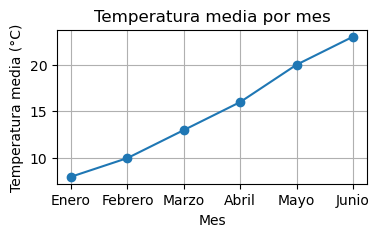

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 2))   
plt.plot(df_clima["Mes"], df_clima["Temperatura"], marker="o")   
plt.title("Temperatura media por mes")
plt.xlabel("Mes")
plt.ylabel("Temperatura media (°C)")
plt.grid(True)
plt.show()

Toda instrucción que comienza por `plt` que no son órdenes propias de Python básico, son funciones de la biblioteca `matplotlib`.

**Explicación de cada instrucción**

- `plt.figure(figsize=(6, 3))`: La función `plt.figure()` crea una nueva figura, es decir, el espacio donde se dibujará el gráfico y tiene el argumento `figsize`que se instancia (`=`) a un tamaño dado '(ancho, alto)'. No es obligatorio indicar el tamaño. Si no lo hacemos, Matplotlib utiliza un tamaño predeterminado.
- `plt.plot(df_clima["Mes"], df_clima["Temperatura"], marker="o")`: Dibuja un gráfico de líneas.
La función `plot()` recibe en sus argumentos los datos que se quieren representar, `df_clima["Mes"]`son valores del eje horizontal y `df_clima["Temperatura"]`son los valores del eje vertical. Además, se puede indicar `marker="o"`que dibuja un círculo en cada punto de datos.
- `plt.title("Temperatura media por mes")`: Añade el título del gráfico. 
- `plt.xlabel("Mes")`: Añade la etiqueta del eje horizontal, que representa los meses.
- `plt.ylabel("Temperatura media (°C)")`: Añade la etiqueta del eje vertical.
- `plt.grid(True)`: Muestra una cuadrícula de referencia que facilita la lectura de los valores del gráfico.
- `plt.show()`: no es necesario en el notebook, pero en otros sistemas sí.


Como podemos observar, hay dos tipos diferentes de funciones:
- Las funciones para crear gráficos, como `plt.plot()`.
- Las funciones para configurar los gráficos, como `plt.figure()`, `plt.title()` o `plt.xlabel()`.

Empecemos por las funciones que crean gráficos

## Clasificación de los principales tipos de gráficos

Las principales funciones para crear gráficos son las siguientes:

| Gráfico | Función | ¿Para qué sirve? | Variables habituales |
|---|---|---|---|
| Sectores  | `plt.pie()` | Mostrar proporciones de un total. | Categorías y valores numéricos |
| Líneas | `plt.plot()` |  Mostrar evolución o tendencias. |X: temporal, categórica o numérica; Y: numérica|
| Barras verticales | `plt.bar()` |  Comparar categorías. | X: categórica; Y: numérica |
| Barras horizontales | `plt.barh()` |  Comparar categorías con etiquetas largas. | Y: categórica; X: numérica |
| Histograma | `plt.hist()`  | Analizar la distribución de valores numéricos. | Numérica |
| Diagrama de caja  | `plt.boxplot()`  | Resumir una distribución e identificar posibles valores atípicos. | Numérica |
| Dispersión  | `plt.scatter()`  | Estudiar la relación entre dos variables numéricas. | X: numérica; Y: numérica|


### Gráfico de sectores: plt.pie()
Categorías y valores numéricos

Representa ***cómo se reparte un total entre categorías***. Es más fácil de interpretar cuando hay pocas categorías. Los argumentos de la función `plt.pie()`son `labels` que muestra las categorías y `autopct` que escribe el porcentaje de cada sector siguiendo el formato:

| Elemento | Significado |
|---|---|
| `%` | Inicia una especificación de formato. |
| `1` | Anchura mínima del campo. |
| `.1` | Indica que queremos un decimal. |
| `f` | Representa un número decimal. |
| `%%` | Muestra el símbolo `%` literal. |

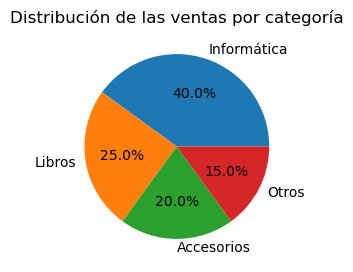

In [24]:
categorias = ["Informática", "Libros", "Accesorios", "Otros"]
ventas = [40, 25, 20, 15]

plt.figure(figsize=(3, 3))
plt.pie(ventas, labels=categorias, autopct="%1.1f%%")
plt.title("Distribución de las ventas por categoría")
plt.show()

### Gráfico de líneas: plt.plot(): 
X: temporal, categórica o numérica; Y: numérica

Sirve para observar la evolución de una variable, por ejemplo, la temperatura a lo largo de los meses.
Las líneas son especialmente útiles cuando el orden de los datos tiene significado, por ejemplo, en una serie temporal.


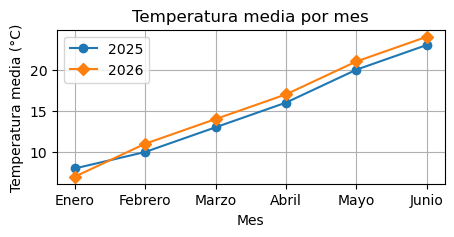

In [26]:
import pandas as pd

datos_2025 = {
    "Mes": ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio"],
    "Temperatura": [8, 10, 13, 16, 20, 23],
    "Precipitación": [85, 70, 60, 45, 35, 25]
}

df_2025 = pd.DataFrame(datos_2025)

datos_2026 = {
    "Mes": ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio"],
    "Temperatura": [7, 11, 14, 17, 21, 24],
    "Precipitación": [90, 65, 55, 50, 30, 20]
}

df_2026 = pd.DataFrame(datos_2026)

plt.figure(figsize=(5, 2))
plt.plot(df_2025["Mes"], df_2025["Temperatura"], marker="o", label="2025")
plt.plot(df_2026["Mes"], df_2026["Temperatura"], marker="D", label="2026")
plt.title("Temperatura media por mes")
plt.xlabel("Mes")    
plt.ylabel("Temperatura media (°C)")
plt.legend()
plt.grid(True)
plt.show()


**Interpretación:** cada punto representa la temperatura media de un mes. Las líneas ayudan a ver tendencias y cambios.

 La temperatura media aumenta de enero a junio en ambos años. 

### Gráfico de barras: plt.bar()
X: categórica; Y: numérica

Un gráfico de barras permite **comparar cantidades entre distintas categorías**. Por ejemplo, podemos comparar la temperatura media de cada mes.

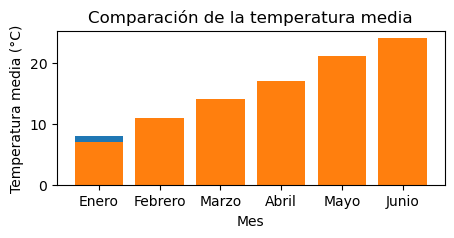

In [29]:
plt.figure(figsize=(5, 2))
plt.bar(df_2025["Mes"], df_2025["Temperatura"])
plt.bar(df_2026["Mes"], df_2026["Temperatura"])
plt.title("Comparación de la temperatura media")
plt.xlabel("Mes")
plt.ylabel("Temperatura media (°C)")
plt.show()


Las barras se solapan porque se dibujan en las mismas posiciones para los dos DataFrames.
Veamos dos formas de solucionarlo.

***Solución 1***

Desplazar ligeramente la posición de cada grupo de barras. Para esto se necesita la biblioteca `numpy`.

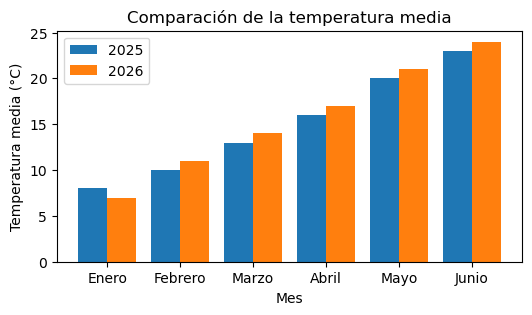

In [32]:
import numpy as np

posiciones = np.arange(len(df_2025["Mes"]))  # crea las posiciones de los meses: 0, 1, 2, 3, 4 y 5.
ancho = 0.40   # la anchura de cada barra.

plt.figure(figsize=(6, 3))

plt.bar(posiciones - ancho/2, df_2025["Temperatura"],   # desplaza las barras de df_2025 hacia la izquierda
        width=ancho, label="2025")

plt.bar(posiciones + ancho/2, df_2026["Temperatura"],   # desplaza las barras de df_2026 hacia la derecha
        width=ancho, label="2026")

plt.title("Comparación de la temperatura media")
plt.xlabel("Mes")
plt.ylabel("Temperatura media (°C)")

plt.xticks(posiciones, df_2025["Mes"])   # pone los nombres de los meses en el eje X, en lugar de 0, 1, 2...

plt.legend()

***Solución 2***

Para mostrar las barras una al lado de la otra, en lugar de superponerlas, se puede crear un nuevo dataframe con las temperaturas medias de ambos años y utilizar `plot(kind="bar")`. A este nuevo dataframe le aplicamos `df_temp.plot()`que es un método de `Pandas`, mientras que `plt.bar()` es una función de `Matplotlib`. Ambos permiten crear gráficos de barras, pero funcionan de forma diferente. 


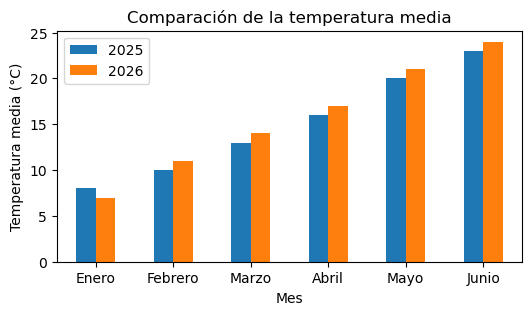

In [34]:
df_temp = pd.DataFrame({
    "Mes": df_2025["Mes"],
    "2025": df_2025["Temperatura"],
    "2026": df_2026["Temperatura"]
})

df_temp.plot(x="Mes", y=["2025", "2026"], kind="bar", figsize=(6, 3))

plt.title("Comparación de la temperatura media")
plt.xlabel("Mes")
plt.ylabel("Temperatura media (°C)")
plt.xticks(rotation=0)
plt.show()


**Interpretación:** la altura de cada barra indica las temperaturas medias.

  Las barras permiten comparar visualmente las temperaturas medias de cada mes. El gráfico de líneas facilita observar la evolución y las tendencias entre meses consecutivos. Ambos pueden servir para comparar valores, pero cada uno enfatiza un aspecto diferente.

### Gráfico de barras horizontales: plt.barh()
Y: categórica; X: numérica

Es útil cuando las categorías tienen nombres largos

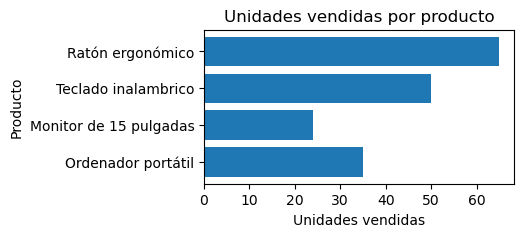

In [37]:
productos = ["Ordenador portátil", "Monitor de 15 pulgadas", "Teclado inalambrico", "Ratón ergonómico"]
unidades_producto = [35, 24, 50, 65]

datos = {
    "Productos": productos,
    "UP": unidades_producto
}

df = pd.DataFrame(datos)

plt.figure(figsize=(4, 2))
plt.barh(df["Productos"], df["UP"])
plt.title("Unidades vendidas por producto")
plt.xlabel("Unidades vendidas")
plt.ylabel("Producto")
plt.show()

### Histograma: plt.hist()
Numérica

Un histograma representa ***la distribución de una variable numérica***. Agrupa valores numéricos en intervalos y muestra cuántas observaciones pertenecen a cada intervalo. 

**Importante:** en un histograma las barras representan intervalos consecutivos de una variable numérica. En un gráfico de barras, en cambio, se comparan categorías diferenciadas.

Por ejemplo, tenemos las notas de 30 estudiantes y queremos saber si se concentran alrededor del aprobado, si predominan las notas altas o si hay muchas notas bajas.

Text(0, 0.5, 'Número de estudiantes')

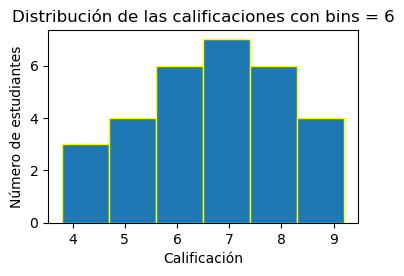

In [39]:
calificaciones = [
    4.2, 5.1, 6.3, 7.0, 5.8, 8.1, 6.7, 7.4, 9.0, 5.5,
    6.1, 7.8, 8.3, 4.9, 6.9, 7.2, 5.7, 8.7, 6.5, 7.1,
    3.8, 4.5, 9.2, 6.0, 7.6, 8.0, 5.3, 6.8, 7.9, 5.9
]

df = pd.DataFrame({"Calificación": calificaciones})

plt.figure(figsize=(4, 2.5))
plt.hist(df["Calificación"], bins=6, edgecolor="yellow")
plt.title("Distribución de las calificaciones con bins = 6")
plt.xlabel("Calificación")
plt.ylabel("Número de estudiantes")

¿Qué significa cada argumento?
- `df["Calificación"]`: lista de valores numéricos que queremos representar.
- `bins=6`: divide el rango de los datos en seis intervalos. Como la nota mínima e `3.8` y la  nota máxima es 9.2, la diferencia entre ambas es '9.2-3.8=5.4' y `5.4 / 6 = 0.9`. Así que, los intervalos son:

    | Intervalo aproximado | Frecuencia |
    |---|---:|
    | 3,8–4,7 | 3 |
    | 4,7–5,6 | 4 |
    | 5,6–6,5 | 6 |
    | 6,5–7,4 | 7 |
    | 7,4–8,3 | 6 |
    | 8,3–9,2 | 4 |

- edgecolor="yellow": dibuja los bordes de las barras en negro.

El histograma permite observar de un vistazo dónde se concentran las calificaciones, cuáles son los intervalos más frecuentes y si existen pocos o muchos valores en los extremos.
El eje horizontal representa los intervalos de notas y el eje vertical indica cuántos estudiantes tienen notas dentro de cada intervalo.


En general:
- Pocos intervalos: resumen más general de la distribución.
- Muchos intervalos: más detalle, aunque puede resultar más difícil identificar el patrón global.
No existe un número de intervalos óptimo para todos los conjuntos de datos.

Si queremos ver el histograma con los límites de los intervalos en el eje x en vez de los números naturales, debemos recoger de `plt.hist` la tupla *frecuencias, limites, barras*, en nuestro caso solo nos interesan los límites, así que ponemos `_` en los componentes de la tupla que no nos interesan. 
Depués calculamos los extremos izquierdo y el derecho de cada intervalo mediante un for usando el formato `:.1f` que usa `:`para separar la expresión de su formato, `.1` que muestra una cifra decimal y `f` que indica que queremos representar el número en formato decimal de punto fijo.
Además, hay una `f`inicial que sirve para insertar variables y expresiones dentro de una cadena de texto.

Para colocar las etiquetas calculadas, utilizamos `plt.xticks()` con los puntos *centros* donde se quieren colocar. 
Aquí usamos `limites[:-1]` que selecciona todos los elementos excepto el último y `limites[1:]`que significa seleccionar todos los elementos desde la posición 1 hasta el final, incluido el último.

Text(0, 0.5, 'Número de estudiantes')

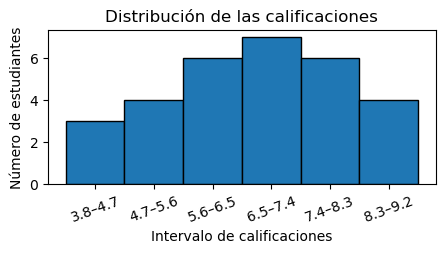

In [41]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(5, 2))

# limites contiene los extremos de los intervalos.
_ , limites, _ = plt.hist(
    df["Calificación"], bins=6, edgecolor="black"
)

# Crear las etiquetas de los intervalos
etiquetas = []
for i in range(len(limites) - 1):
    etiqueta = f"{limites[i]:.1f}–{limites[i+1]:.1f}"  # f" " str; { } variable;  
    etiquetas.append(etiqueta)

# Colocar las etiquetas en el centro de cada barra
centros = (limites[:-1] + limites[1:]) / 2
plt.xticks(centros, etiquetas, rotation = 20)

plt.title("Distribución de las calificaciones")
plt.xlabel("Intervalo de calificaciones")
plt.ylabel("Número de estudiantes")


Con los mismos datos y 10 bins sería el siguiente gráfico.

Text(0, 0.5, 'Número de estudiantes')

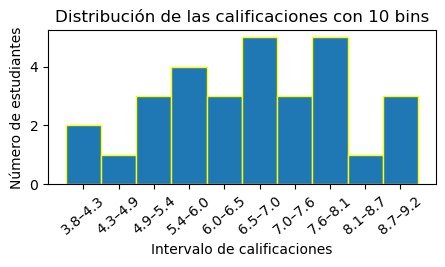

In [43]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(5, 2))

# limites contiene los extremos de los intervalos.
_ , limites, _ = plt.hist(
    df["Calificación"], bins = 10, edgecolor="yellow"
)

# Crear las etiquetas de los intervalos
etiquetas = []
for i in range(len(limites) - 1):
    etiqueta = f"{limites[i]:.1f}–{limites[i+1]:.1f}"
    etiquetas.append(etiqueta)

# Colocar las etiquetas en el centro de cada barra
centros = (limites[:-1] + limites[1:]) / 2
plt.xticks(centros, etiquetas, rotation = 40)

plt.title("Distribución de las calificaciones con 10 bins")
plt.xlabel("Intervalo de calificaciones")
plt.ylabel("Número de estudiantes")


### Diagrama de caja: plt.boxplot()
Numérica

Un ***diagrama de caja***, también llamado ***boxplot***, resume una distribución numérica mediante cuartiles, mediana y posibles valores atípicos. Es útil cuando queremos conocer la posición central de los datos, su dispersión y si hay observaciones que se alejan del resto.

Los elementos del diagrama de caja son:

- Mediana ($Q_2$)
Divide los datos ordenados en dos mitades: aproximadamente la mitad queda por debajo y la otra mitad por encima.

- Primer y tercer cuartil ($Q_1$ y $Q_3$) delimitan la caja. 
    * $Q_1$: primer cuartil, el 25 % de los datos queda por debajo.
    * $Q_3$: tercer cuartil, el 75 % de los datos queda por debajo.
    $$ $$

- Bigotes, sSe extienden hasta los valores más extremos que no se consideran atípicos según la regla habitual de Matplotlib, que utiliza la regla de 1,5 veces el *rango intercuartílico* ( $RIC = Q_3 - Q_1$ ). De esta forma, los límites habituales para identificar posibles valores atípicos son:

    $$L_{\mathrm{inf}}=Q_1-1,5 * RIC$$

    $$L_{\mathrm{sup}}=Q_3+1,5 * RIC$$


- Valores atípicos potenciales
Se representan individualmente cuando quedan fuera de los límites de los bigotes.

In [45]:
from IPython.display import HTML, display

# Definimos el espacio en píxeles que quieres dejar a la izquierda (ej. 100px)
espacio_izq = "150px"

display(
    HTML(
        '<div style="text-align: center;">'
        '<img src="./Imagen/Diagrama_de_caja.jpg" width="600">'
        '<img src="./Imagen/boxplot-diagrama.png" width="800">'
        '</div>'
    )
)

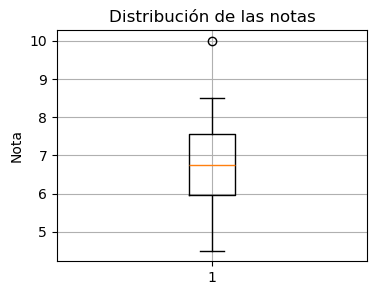

In [46]:
notas_grupo = [4.5, 5.0, 5.2, 5.5, 5.8, 6.0, 6.1, 6.3, 6.5, 6.7,
               6.8, 7.0, 7.1, 7.2, 7.5, 7.7, 8.0, 8.2, 8.5, 10.0]

plt.figure(figsize=(4, 3))
plt.boxplot(notas_grupo)
plt.title("Distribución de las notas")
plt.ylabel("Nota")
plt.grid()
plt.show()

El diagrama de caja resume la distribución sin necesidad de mostrar cada observación individual.

- $Q_1$ Primer cuartil: 5,95. El borde inferior de la caja.
- $Q_2$ Mediana: 6,75. La línea dentro de la caja.
- $Q_3$ Tercer cuartil: 7,55. El borde superior.
- RIC: 1,60. La altura de la caja.
- Valor atípico: 10,0, que queda ligeramente por encima del límite superior habitual de 1,5 veces el rango intercuartílico


### Diagrama de dispersión: plt.scatter()
X: numérica; Y: numérica

Un diagrama de dispersión permite explorar si existe una relación entre dos variables numéricas. Si los puntos muestran una tendencia, podemos observar una asociación entre las variables. Sin embargo, el gráfico por sí solo no demuestra que una variable cause la otra.




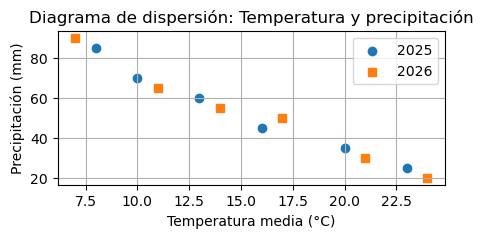

In [49]:
plt.figure(figsize=(5, 2))

plt.scatter(df_2025["Temperatura"], df_2025["Precipitación"], marker="o", label="2025")
plt.scatter(df_2026["Temperatura"], df_2026["Precipitación"], marker="s", label="2026")

plt.xlabel("Temperatura media (°C)")
plt.ylabel("Precipitación (mm)")
plt.title("Diagrama de dispersión: Temperatura y precipitación")
plt.legend()
plt.grid(True)


**Interpretación**

En estos datos, los puntos tienden a bajar de izquierda a derecha, esto significa que los meses más cálidos suelen presentar menos precipitaciones. Además, como los círculos y los cuadrados se concentran en zonas parecidas, los patrones mensuales podrían ser similares.

Observación: un gráfico puede sugerir una asociación, pero por sí solo no demuestra que una variable sea la causa de la otra. En nuestro ejemplo, la relación entre temperatura y precipitación no demuestra que una variable cause la otra.


## Funciones de configuración

Las funciones de configuración nos permiten personalizar los gráficos modificando elementos como el tamaño, el título, las etiquetas, la leyenda, la cuadrícula o los límites de los ejes. Estas funciones se  resumen en la siguiente tabla.

En Matplotlib, algunas instrucciones habituales son:

| Función | Utilidad |
|---|---|
| `plt.figure()` | Crear una figura y configurar su tamaño. |
| `plt.title()` | Añadir un título. |
| `plt.xlabel()` | Etiquetar el eje X. |
| `plt.ylabel()` | Etiquetar el eje Y. |
| `plt.legend()` | Mostrar una leyenda. |
| `plt.grid()` | Activar o desactivar la cuadrícula. |
| `plt.xlim()` | Establecer los límites del eje X. |
| `plt.ylim()` | Establecer los límites del eje Y. |
| `plt.xticks()` |	Configurar las marcas y etiquetas del eje X. |
| `plt.yticks()` |	Configurar las marcas y etiquetas del eje Y. |
| `plt.savefig()` | Guardar el gráfico en un fichero. |
| `plt.suptitle()` | Añadir un título general a una figura con varios gráficos. |
| `plt.tight_layout()` | Ajustar automáticamente los espacios para evitar solapamientos. |
| `plt.subplot()` | Crear y seleccionar una posición para un gráfico dentro de una cuadrícula. |
| `plt.subplots()` | Crear una figura y uno o varios ejes para dibujar gráficos. |
| `plt.axis()` | Configurar los límites de los ejes o su apariencia. |
| `plt.tick_params()` | Personalizar las marcas de los ejes, sus etiquetas y su apariencia. |
| `plt.text()` | Añadir texto en una posición concreta del gráfico. |
| `plt.annotate()` | Añadir anotaciones, opcionalmente con flechas. |
| `plt.show()` | Mostrar la figura. |


Los marcadores se utilizan para resaltar los puntos de datos en gráficos de líneas o de dispersión usando el argumento `marker`.
La lista de las opciones de marcadores son:

| Símbolo | Nombre | Símbolo | Nombre |
|:---:|---|:---:|---|
| '.' | Punto | ',' | Píxel |
| 'o' | Círculo | 'v' | Triángulo hacia abajo |
| '^' | Triángulo hacia arriba | '<' | Triángulo hacia la izquierda |
| '>' | Triángulo hacia la derecha | 's' | Cuadrado |
| 'p' | Pentágono | '*' | Estrella |
| 'h' | Hexágono 1 | 'H' | Hexágono 2 |
| 'd' | Diamante delgado | 'D' | Diamante ancho |
| '+' | Signo de más | 'x' | Letra X |
| 'X' | X rellena o gruesa | 'P' | Signo de más relleno o grueso |
| '_' | Línea horizontal | '|' | Línea vertical |
| '1' | Triángulo hacia abajo con líneas desde el centro | '2' | Triángulo hacia arriba con líneas desde el centro |
| '3' | Triángulo hacia la izquierda con líneas desde el centro | '4' | Triángulo hacia la derecha con líneas desde el centro |


 Además, también veremos cómo modificar colores, tipos de línea y marcadores mediante argumentos como `color`, `linestyle`, `linewidth`, etc.
 
| Argumento | Utilidad | Ejemplo |
|---|---|---|
| `color` | Cambiar el color de la línea o los puntos. | `color='red'` |
| `linestyle` | Cambiar el estilo de la línea. | `linestyle='--'` |
| `linewidth` | Modificar el grosor de la línea. | `linewidth=2` |
| `marker` | Elegir el marcador de los puntos. | `marker='o'` |
| `markersize` | Modificar el tamaño de los marcadores en `plt.plot()`. | `markersize=8` |
| `markerfacecolor` | Cambiar el color de relleno del marcador. | `markerfacecolor='yellow'` |
| `markeredgecolor` | Cambiar el color del borde del marcador. | `markeredgecolor='black'` |
| `alpha` | Ajustar la transparencia. | `alpha=0.5` |


Colores: se pueden utilizar nombres de colores completos, como 'blue', 'orange' o 'purple', y códigos hexadecimales, como '#FF5733'.


| Valor | Color | Valor | Color |
|---|---|---|---|
| `'b'` | Azul | `'g'` | Verde |
| `'r'` | Rojo | `'c'` | Cian |
| `'m'` | Magenta | `'y'` | Amarillo |
| `'k'` | Negro | `'w'` | Blanco |



# Referencias

Documentación de la biblioteca `matplotlib`:

- Tipos de gráficos (Plot types): clasificación de las funciones de representación, con ejemplos visuales. https://matplotlib.org/stable/plot_types/index.html

- Galería de ejemplos (Examples Gallery): ejemplos más completos https://matplotlib.org/stable/gallery/index.html

- Resumen de funciones de pyplot: referencia de las funciones disponibles en pyplot.  https://matplotlib.org/stable/api/pyplot_summary.html

También, hay varias *cheat sheets* (*hojas de referencia rápida*) de `Matplotlib` que vienen muy bien para consultar las instrucciones más habituales sin tener que memorizar todos los comandos.

- Chuleta oficial de Matplotlib: https://matplotlib.org/cheatsheets/cheatsheets.pdf

Documentación de Python en general.

- [Tutorial de Python. Por Guido Van Rossum](http://docs.python.org.ar/tutorial/pdfs/TutorialPython3.pdf)
- [Big Data. Análisis de datos con Python. Sarasa Cabezuelo, Antonio; García Ruiz, Yolanda Aditorial Garceta. ISBN: 978-84-1622-883-6](http://www.garceta.es/libro.php?ISBN=978-84-1622-883-6)